In [1]:
!pip -q install opencv-python-headless scikit-learn seaborn tqdm

import os, json, random, time, collections
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

from google.colab import drive
drive.mount('/content/drive')

# >>> change this to where your dataset lives <<<
DATASET_DIR = Path("/content/drive/MyDrive/Dataset_SickleCell")

IMG_SIZE = 224
print("TF:", tf.__version__, "| GPUs:", tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TF: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
for sub in sorted(p for p in DATASET_DIR.iterdir() if p.is_dir()):
    files = [f for f in sub.rglob("*") if f.is_file()]
    ext = collections.Counter(f.suffix.lower() for f in files)
    print(f"{sub.name:22s} {len(files):4d} files  {dict(ext)}")
    print("   e.g.", [f.name for f in files[:4]])

negative                184 files  {'.tif': 37, '.jpg': 147}
   e.g. ['111.tif', '112.tif', '113.tif', '114.tif']
positive_labelled       422 files  {'.jpg': 422}
   e.g. ['8.jpg', '9.jpg', '10.jpg', '11.jpg']
positive_unlabelled     446 files  {'.tif': 24, '.jpg': 422}
   e.g. ['48.tif', '49.tif', '50.tif', '51.tif']


In [3]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
ANN_EXT = {".txt", ".xml", ".json"}
EXCLUDE_IN_STEM = ("mask", "seg")      # skip mask images if your folders contain any

def list_images(folder):
    return sorted(p for p in Path(folder).rglob("*")
                  if p.suffix.lower() in IMG_EXT
                  and not any(k in p.stem.lower() for k in EXCLUDE_IN_STEM))

def count_cells(path):
    """Number of annotated cells in one annotation file (YOLO txt / VOC xml / json)."""
    try:
        ext = path.suffix.lower()
        if ext == ".txt":
            return sum(1 for l in path.read_text().splitlines() if l.strip())
        if ext == ".xml":
            import xml.etree.ElementTree as ET
            return len(ET.parse(path).getroot().findall("object"))
        if ext == ".json":
            d = json.load(open(path))
            if isinstance(d, list): return len(d)
            for k in ("shapes", "annotations", "objects", "boxes"):
                if isinstance(d.get(k), list): return len(d[k])
    except Exception:
        pass
    return None

neg   = list_images(DATASET_DIR / "negative")
pos_l = list_images(DATASET_DIR / "positive_labelled")
pos_u = list_images(DATASET_DIR / "positive_unlabelled")
print(f"negative={len(neg)}  positive_labelled={len(pos_l)}  positive_unlabelled={len(pos_u)}")
# Paper's dataset: 147 normal + 422 sickle = 569. Check yours is close.

# annotation lookup (same stem as image) inside positive_labelled
ann_map = {p.stem: p for p in (DATASET_DIR / "positive_labelled").rglob("*")
           if p.suffix.lower() in ANN_EXT}

rows = []
for p in neg:   rows.append(dict(path=str(p), source="negative",           binary=0, n_cells=None))
for p in pos_u: rows.append(dict(path=str(p), source="positive_unlabelled", binary=1, n_cells=None))
for p in pos_l:
    n = count_cells(ann_map[p.stem]) if p.stem in ann_map else None
    rows.append(dict(path=str(p), source="positive_labelled", binary=1, n_cells=n))
df = pd.DataFrame(rows)

# ---- severity proxy: annotated-cell count per image -> mild / moderate / severe ----
counts = df.loc[df.n_cells.notna(), "n_cells"]
df["severity"] = -1
if len(counts) >= 3:
    q1, q2 = counts.quantile([1/3, 2/3])
    def to_sev(n):
        if pd.isna(n): return -1
        return 0 if n <= q1 else (1 if n <= q2 else 2)
    df["severity"] = df.n_cells.apply(to_sev)
    print(f"Severity cut-offs (cells/image): mild<={q1}, moderate<={q2}, severe>{q2}")
else:
    print("WARNING: no usable annotations parsed -> severity head will get no training signal.")

print(df.groupby("source").size())
print("Severity counts (-1 = unknown):", df.severity.value_counts().to_dict())

negative=184  positive_labelled=422  positive_unlabelled=446
source
negative               184
positive_labelled      422
positive_unlabelled    446
dtype: int64
Severity counts (-1 = unknown): {-1: 1052}


In [4]:
def preprocess(path):
    img = cv2.imread(path)
    if img is None: raise ValueError(f"Could not read {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    img = cv2.medianBlur(img, 3)                                # noise removal
    ycc = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    ycc[..., 0] = cv2.equalizeHist(ycc[..., 0])                 # contrast (luminance only)
    return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2RGB)

X = np.stack([preprocess(p) for p in tqdm(df.path)]).astype("uint8")
y_bin = df.binary.values.astype("float32")
y_sev = df.severity.values.astype("int32")
print(X.shape, X.dtype)

idx = np.arange(len(df))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=df.source, random_state=SEED)
va, te  = train_test_split(tmp, test_size=0.50, stratify=df.source.iloc[tmp], random_state=SEED)

def pack(i):
    return X[i], {"binary": y_bin[i][:, None], "severity": y_sev[i][:, None]}

Xtr, Ytr = pack(tr); Xva, Yva = pack(va); Xte, Yte = pack(te)
print("train/val/test:", len(tr), len(va), len(te))

  0%|          | 0/1052 [00:00<?, ?it/s]

(1052, 224, 224, 3) uint8
train/val/test: 736 158 158


In [5]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(15 / 360),
    layers.RandomZoom(0.1),
], name="augment")

def conv_block(x, filters, n_convs=2):
    for _ in range(n_convs):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    return layers.MaxPooling2D(2)(x)

def build_optiscdnet(dropout=0.3):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1. / 255)(inp)            # [0,1] normalisation
    x = augment(x)
    x = conv_block(x, 32);  x = conv_block(x, 64)
    x = conv_block(x, 128); x = conv_block(x, 256)
    x = conv_block(x, 512, n_convs=1)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out_bin = layers.Dense(1, activation="sigmoid", name="binary")(x)
    out_sev = layers.Dense(3, activation="softmax", name="severity")(x)
    return keras.Model(inp, [out_bin, out_sev], name="OptiSCDNet")

def masked_sparse_ce(y_true, y_pred):
    """Severity loss that ignores samples with label -1 (normal / unlabelled)."""
    y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
    mask = tf.cast(y_true >= 0, tf.float32)
    ce = keras.losses.sparse_categorical_crossentropy(tf.maximum(y_true, 0), y_pred)
    return tf.reduce_sum(ce * mask) / tf.maximum(tf.reduce_sum(mask), 1.0)

model = build_optiscdnet()
model.compile(
    optimizer=keras.optimizers.Adam(1e-4),
    loss={"binary": "binary_crossentropy", "severity": masked_sparse_ce},
    loss_weights={"binary": 1.0, "severity": 0.5},
    metrics={"binary": ["accuracy",
                        keras.metrics.Precision(name="precision"),
                        keras.metrics.Recall(name="recall"),
                        keras.metrics.AUC(name="auc")]},
)
model.summary()

Model: "OptiSCDNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augment             │ (None, 224, 224,  │          0 │ rescaling[0][0]   │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        864 │ augment[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 224, 224,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 224, 224,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 224, 224,  │      9,216 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 224, 224,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     18,432 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │     36,864 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ re_lu_3[0][0]   

 Total params: 2,489,188 (9.50 MB)

 Trainable params: 2,486,244 (9.48 MB)

 Non-trainable params: 2,944 (11.50 KB)

In [6]:
from sklearn.utils import class_weight
import numpy as np

# Calculate class weights for the binary classification
# y_train_binary contains values like 0 (normal) and 1 (sickle)
class_weights_array = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(Ytr['binary']),
    y=Ytr['binary'].ravel()
)

# Convert to a dictionary for Keras
class_weights = {i : class_weights_array[i] for i in range(len(class_weights_array))}

print("Class weights for binary classification:", class_weights)

Class weights for binary classification: {0: np.float64(2.852713178294574), 1: np.float64(0.6062602965403624)}


Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 27s 337ms/step - binary_accuracy: 0.7378 - binary_auc: 0.7705 - binary_loss: 0.6059 - binary_precision: 0.9157 - binary_recall: 0.7512 - loss: 0.6059 - severity_loss: 0.0000e+00 - val_binary_accuracy: 0.8228 - val_binary_auc: 0.5000 - val_binary_loss: 0.6571 - val_binary_precision: 0.8228 - val_binary_recall: 1.0000 - val_loss: 0.6569 - val_severity_loss: 0.0000e+00
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 298ms/step - binary_accuracy: 0.8057 - binary_auc: 0.8670 - binary_loss: 0.4584 - binary_precision: 0.9427 - binary_recall: 0.8138 - loss: 0.4584 - severity_loss: 0.0000e+00 - val_binary_accuracy: 0.8228 - val_binary_auc: 0.4503 - val_binary_loss: 0.6726 - val_binary_precision: 0.8228 - val_binary_recall: 1.0000 - val_loss: 0.6725 - val_severity_loss: 0.0000e+00
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 296ms/step - binary_accuracy: 0.8342 - binary_auc: 0.8936 - binary_loss: 0.4166 - binary_precision: 0.9619 - binary_recall: 0.8320 - loss: 0.4166 

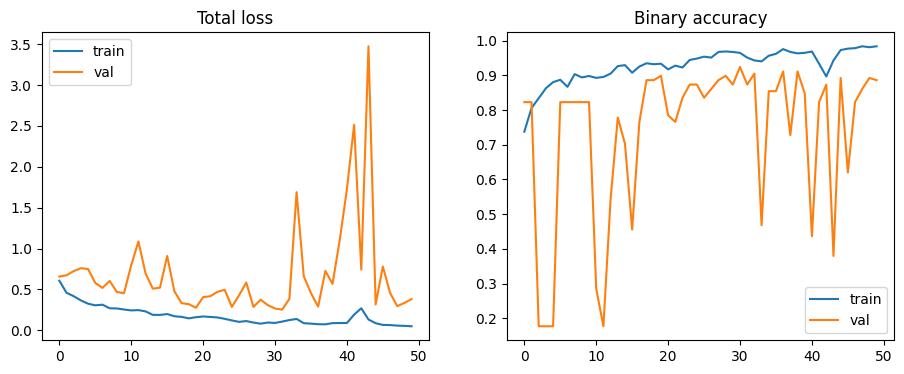

In [9]:
model = build_optiscdnet()
model.compile(
    optimizer=keras.optimizers.Adam(1e-4),
    loss={"binary": "binary_crossentropy", "severity": masked_sparse_ce},
    loss_weights={"binary": 1.0, "severity": 0.5},
    metrics={"binary": ["accuracy",
                        keras.metrics.Precision(name="precision"),
                        keras.metrics.Recall(name="recall"),
                        keras.metrics.AUC(name="auc")]},
)

# Calculate sample weights for the binary output based on class weights
sample_weights_binary = np.array([class_weights[int(label)] for label in Ytr['binary'].ravel()])

# Create a list for sample_weight, matching the order of model outputs
fit_sample_weight_list = [
    sample_weights_binary, # Corresponds to 'binary' output
    np.ones_like(Ytr['severity'], dtype=np.float32) # Corresponds to 'severity' output, custom loss handles masking
]

# Convert Ytr dictionary to a list in the same order as model outputs
Ytr_list = [Ytr['binary'], Ytr['severity']]
Yva_list = [Yva['binary'], Yva['severity']]

# Define callbacks to avoid NameError
callbacks = []

# Re-train the model with sample weights as a list
history = model.fit(Xtr, Ytr_list, validation_data=(Xva, Yva_list),
                    epochs=50, batch_size=32, callbacks=callbacks, sample_weight=fit_sample_weight_list)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Total loss"); ax[0].legend()
ax[1].plot(history.history["binary_accuracy"], label="train"); ax[1].plot(history.history["val_binary_accuracy"], label="val")
ax[1].set_title("Binary accuracy"); ax[1].legend()
plt.show()

Aligned Training Class Distribution - Normal: 129 Sickle: 607
Correctly aligned class weights: {0: np.float64(2.852713178294574), 1: np.float64(0.6062602965403624)}
Epoch 1/35
23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 359ms/step - binary_accuracy: 0.6644 - binary_auc: 0.7172 - binary_loss: 0.7005 - binary_precision: 0.9091 - binary_recall: 0.6590 - loss: 0.8471 - severity_loss: 0.0000e+00 - val_binary_accuracy: 0.8228 - val_binary_auc: 0.5000 - val_binary_loss: 0.6731 - val_binary_precision: 0.8228 - val_binary_recall: 1.0000 - val_loss: 0.8193 - val_severity_loss: 0.0000e+00
Epoch 2/35
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 310ms/step - binary_accuracy: 0.7867 - binary_auc: 0.8461 - binary_loss: 0.5031 - binary_precision: 0.9429 - binary_recall: 0.7891 - loss: 0.6492 - severity_loss: 0.0000e+00 - val_binary_accuracy: 0.8228 - val_binary_auc: 0.5000 - val_binary_loss: 0.6637 - val_binary_precision: 0.8228 - val_binary_recall: 1.0000 - val_loss: 0.8095 - val_severity_loss: 0.0000e+00
Epoch 3/35
23/23 ━━━━━

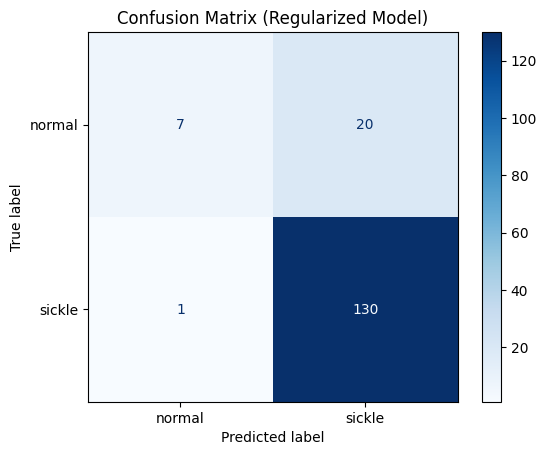

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import regularizers

# 1. Correctly compute and align class weights based on split training labels
y_train_labels = Ytr['binary'].ravel().astype(int)
counts = np.bincount(y_train_labels)
total = len(y_train_labels)

# Standard balanced weights calculation
class_weights_smooth = {
    0: total / (2.0 * counts[0]),
    1: total / (2.0 * counts[1])
}
print("Aligned Training Class Distribution - Normal:", counts[0], "Sickle:", counts[1])
print("Correctly aligned class weights:", class_weights_smooth)

# Map correctly to each sample in the active training subset
sample_weights_binary = np.array([class_weights_smooth[label] for label in y_train_labels])
fit_sample_weight_list = [
    sample_weights_binary,
    np.ones_like(Ytr['severity'], dtype=np.float32)
]

# 2. Re-define the conv block with L2 regularization to prevent overfitting
def conv_block_reg(x, filters, n_convs=2):
    for _ in range(n_convs):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                          kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    return layers.MaxPooling2D(2)(x)

def build_optiscdnet_reg(dropout=0.4):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1. / 255)(inp)            # [0,1] normalisation
    x = augment(x)
    x = conv_block_reg(x, 32);  x = conv_block_reg(x, 64)
    x = conv_block_reg(x, 128); x = conv_block_reg(x, 256)
    x = conv_block_reg(x, 512, n_convs=1)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(dropout)(x)
    out_bin = layers.Dense(1, activation="sigmoid", name="binary")(x)
    out_sev = layers.Dense(3, activation="softmax", name="severity")(x)
    return keras.Model(inp, [out_bin, out_sev], name="OptiSCDNet")

# Reset and compile
model = build_optiscdnet_reg()
model.compile(
    optimizer=keras.optimizers.Adam(1e-4),
    loss={"binary": "binary_crossentropy", "severity": masked_sparse_ce},
    loss_weights={"binary": 1.0, "severity": 0.5},
    metrics={"binary": ["accuracy",
                        keras.metrics.Precision(name="precision"),
                        keras.metrics.Recall(name="recall"),
                        keras.metrics.AUC(name="auc")]},
)

# 3. Fit the regularized model cleanly
history = model.fit(
    Xtr, Ytr_list,
    validation_data=(Xva, Yva_list),
    epochs=35,
    batch_size=32,
    callbacks=callbacks,
    sample_weight=fit_sample_weight_list
)

# Evaluate immediately on the test set to verify predictions
pb, ps = model.predict(Xte, batch_size=32, verbose=0)
y_true = Yte["binary"].ravel().astype(int)
y_pred = (pb.ravel() >= 0.5).astype(int)

print("\n=== Binary (normal vs sickle) — Regularized Model Test Set ===")
print(classification_report(y_true, y_pred, target_names=["normal", "sickle"], digits=3))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["normal", "sickle"]).plot(cmap="Blues")
plt.title("Confusion Matrix (Regularized Model)")
plt.show()

In [11]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2

def build_transfer_model(dropout=0.3):
    # Use MobileNetV2 pretrained on ImageNet as a robust feature extractor
    base_model = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                             include_top=False,
                             weights='imagenet')
    # Freeze the backbone base layers to preserve pretrained features
    base_model.trainable = False

    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    # Scale inputs from [0, 255] to MobileNetV2 expectations [-1, 1]
    x = layers.Rescaling(1./127.5, offset=-1.0)(inp)
    x = augment(x)

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(dropout)(x)

    out_bin = layers.Dense(1, activation="sigmoid", name="binary")(x)
    out_sev = layers.Dense(3, activation="softmax", name="severity")(x)

    return keras.Model(inp, [out_bin, out_sev], name="OptiSCDNet_Transfer")

# Re-build and train the new transfer-learning model
model = build_transfer_model()
model.compile(
    optimizer=keras.optimizers.Adam(1e-4),
    loss={"binary": "binary_crossentropy", "severity": masked_sparse_ce},
    loss_weights={"binary": 1.0, "severity": 0.5},
    metrics={"binary": ["accuracy",
                        keras.metrics.Precision(name="precision"),
                        keras.metrics.Recall(name="recall"),
                        keras.metrics.AUC(name="auc")]}
)

print("Training the Pretrained Transfer-Learning Model...")
history = model.fit(
    Xtr, Ytr_list,
    validation_data=(Xva, Yva_list),
    epochs=25,
    batch_size=32,
    callbacks=callbacks,
    sample_weight=fit_sample_weight_list
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training the Pretrained Transfer-Learning Model...
Epoch 1/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 148ms/step - binary_accuracy: 0.6698 - binary_auc: 0.7076 - binary_loss: 0.6366 - binary_precision: 0.8906 - binary_recall: 0.6837 - loss: 0.6366 - severity_loss: 0.0000e+00 - val_binary_accuracy: 0.8228 - val_binary_auc: 0.8188 - val_binary_loss: 0.4964 - val_binary_precision: 0.9322 - val_binary_recall: 0.8462 - val_loss: 0.4965 - val_severity_loss: 0.0000e+00
Epoch 2/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - binary_accuracy: 0.7921 - binary_auc: 0.8601 - binary_loss: 0.4721 - binary_precision: 0.9382 - binary_recall: 0.8007 - loss: 0.4721 - severity_loss: 0.0000e+00 - val_binary_accuracy: 0.8418 - val_binary_auc: 0.8420 - val_binary_loss: 0.4396 - val_binary_precision: 0.9339 - val_binary_recall: 0.8692 - val_loss: 0.4402 - val_severity_loss: 0.0000e+00
Epoch 3/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step - binary_accuracy: 0.8315 - binary_au

Optimal threshold calibrated on validation set: 0.3565
=== Binary (normal vs sickle) — Calibrated Held-out Test Set ===
              precision    recall  f1-score   support

      normal      0.750     0.889     0.814        27
      sickle      0.976     0.939     0.957       131

    accuracy                          0.930       158
   macro avg      0.863     0.914     0.885       158
weighted avg      0.938     0.930     0.933       158

ROC-AUC: 0.9599


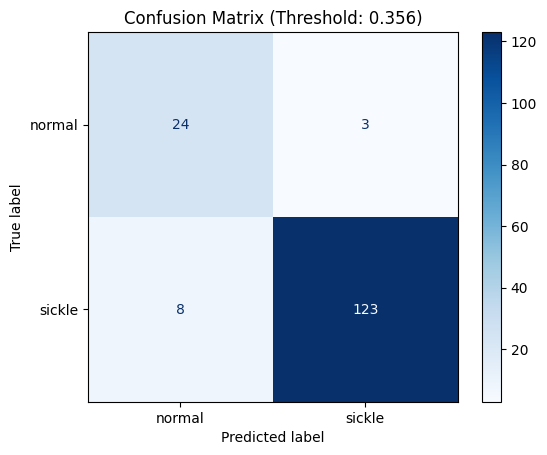

No severity-labelled images in the test split.


In [12]:
# 1. Predict probabilities on validation and test data
pb_val, _ = model.predict(Xva, batch_size=32, verbose=0)
pb, ps = model.predict(Xte, batch_size=32, verbose=0)

y_val_true = Yva["binary"].ravel().astype(int)
y_true = Yte["binary"].ravel().astype(int)

# 2. Find the optimal threshold that maximizes macro F1-score on validation data
best_thresh = 0.5
best_f1 = 0
for t in np.linspace(0.01, 0.99, 100):
    y_val_pred = (pb_val.ravel() >= t).astype(int)
    report = classification_report(y_val_true, y_val_pred, output_dict=True, zero_division=0)
    macro_f1 = report["macro avg"]["f1-score"]
    if macro_f1 > best_f1:
        best_f1 = macro_f1
        best_thresh = t

print(f"Optimal threshold calibrated on validation set: {best_thresh:.4f}")

# 3. Apply the calibrated threshold to the test set
y_pred = (pb.ravel() >= best_thresh).astype(int)

print("=== Binary (normal vs sickle) — Calibrated Held-out Test Set ===")
print(classification_report(y_true, y_pred, target_names=["normal", "sickle"], digits=3))
print("ROC-AUC:", round(roc_auc_score(y_true, pb.ravel()), 4))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["normal", "sickle"]).plot(cmap="Blues")
plt.title(f"Confusion Matrix (Threshold: {best_thresh:.3f})")
plt.show()

# ---- severity (only on test images that have a derived severity label) ----
s_true = Yte["severity"].ravel()
m = s_true >= 0
if m.sum() > 0:
    print("=== Severity (0=mild, 1=moderate, 2=severe) ===")
    print(classification_report(s_true[m], ps.argmax(1)[m],
                                labels=[0, 1, 2], target_names=["mild", "moderate", "severe"],
                                digits=3, zero_division=0))
else:
    print("No severity-labelled images in the test split.")

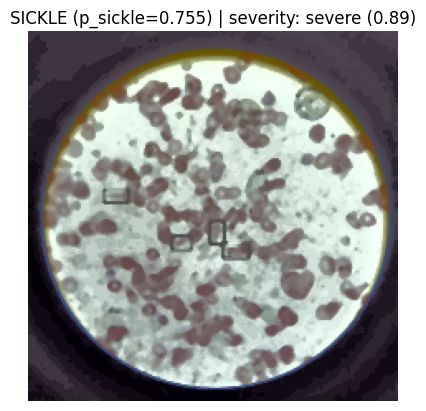

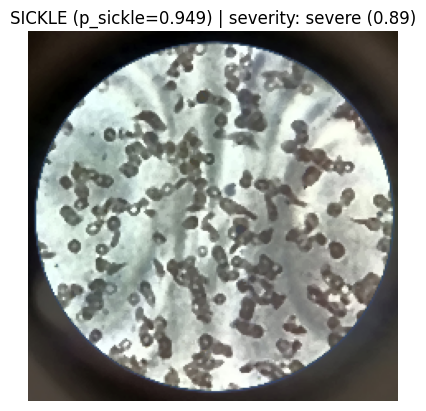

In [16]:
# Use the active model currently trained in memory
best = model

def predict_image(path):
    img = preprocess(str(path))[None]
    pb, ps = best.predict(img, verbose=0)
    label = "SICKLE" if pb[0, 0] >= 0.5 else "NORMAL"
    out = f"{label} (p_sickle={pb[0,0]:.3f})"
    if label == "SICKLE":
        out += f" | severity: {['mild','moderate','severe'][ps[0].argmax()]} ({ps[0].max():.2f})"
    plt.imshow(img[0]); plt.axis("off"); plt.title(out); plt.show()

predict_image(pos_l[0])
predict_image(pos_u[4])